# ATAC-seq Ensemble Report

The goal is to compare the original cluster assignment to the ensemble clustering results.

In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load combined file
combined_sp = sc.read_h5ad("../data/combined.h5ad")

In [4]:
combined_sp.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,...,uniform_density,rna_count_based_density,tangram_celltype,bayesspace,bass,ensemble,scanit,stlearn,graphst,groundtruth
0_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,...,0.00019,0.000245,EN07,4,8,2,1,1,1,1
3_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,...,0.00019,0.000160,EN02,3,3,0,2,2,2,2
4_1,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,...,0.00019,0.000319,P1,1,8,2,3,3,1,3
5_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,...,0.00019,0.000108,IN02,3,3,0,4,2,2,4
6_1,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,...,0.00019,0.000166,EN02,1,11,7,5,4,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,...,0.00019,0.000159,EN02,3,3,0,2,2,2,2
6214_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,...,0.00019,0.000230,IN01,4,10,0,2,1,5,9
6215_1,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,...,0.00019,0.000161,OG1,11,10,0,2,11,2,11
6216_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,...,0.00019,0.000141,IN01,7,2,10,8,1,3,9


In [15]:
combined_sp.obsm

AxisArrays with keys: spatial

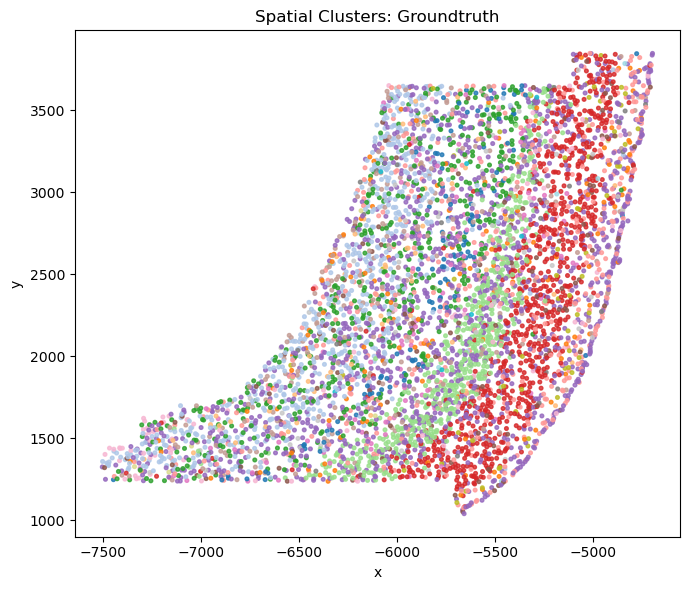

In [9]:
x = combined_sp.obs["centroid_x"]
y_coord = combined_sp.obs["centroid_y"]
y = combined_sp.obs["groundtruth"]

cluster_codes = pd.Series(y).astype('category').cat.codes.to_numpy()
plt.figure(figsize=(7,6))
plt.scatter(x, y_coord, c=cluster_codes, cmap='tab20', s=7, alpha=0.8)
plt.title(f"Spatial Clusters: Groundtruth")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
# plt.savefig("../data/ensemble_input/spatial_groundtruth.png")
# plt.close()

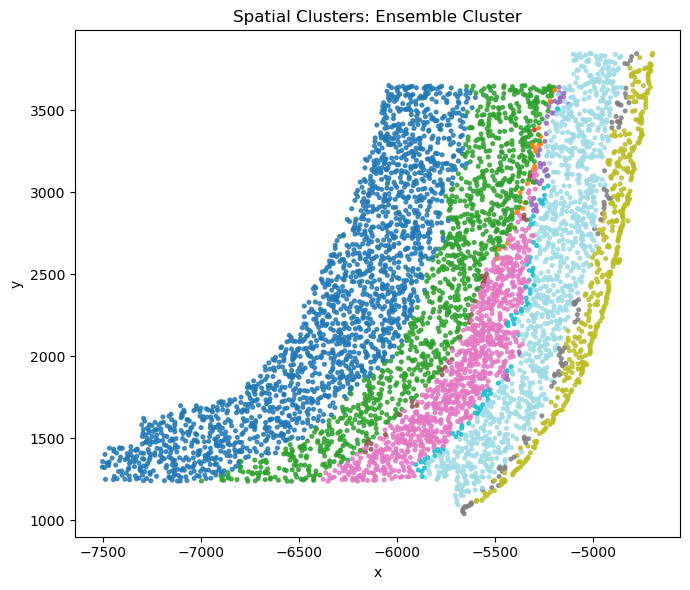

In [10]:
x = combined_sp.obs["centroid_x"]
y_coord = combined_sp.obs["centroid_y"]
y = combined_sp.obs["ensemble"]

cluster_codes = pd.Series(y).astype('category').cat.codes.to_numpy()
plt.figure(figsize=(7,6))
plt.scatter(x, y_coord, c=cluster_codes, cmap='tab20', s=7, alpha=0.8)
plt.title(f"Spatial Clusters: Ensemble Cluster")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()

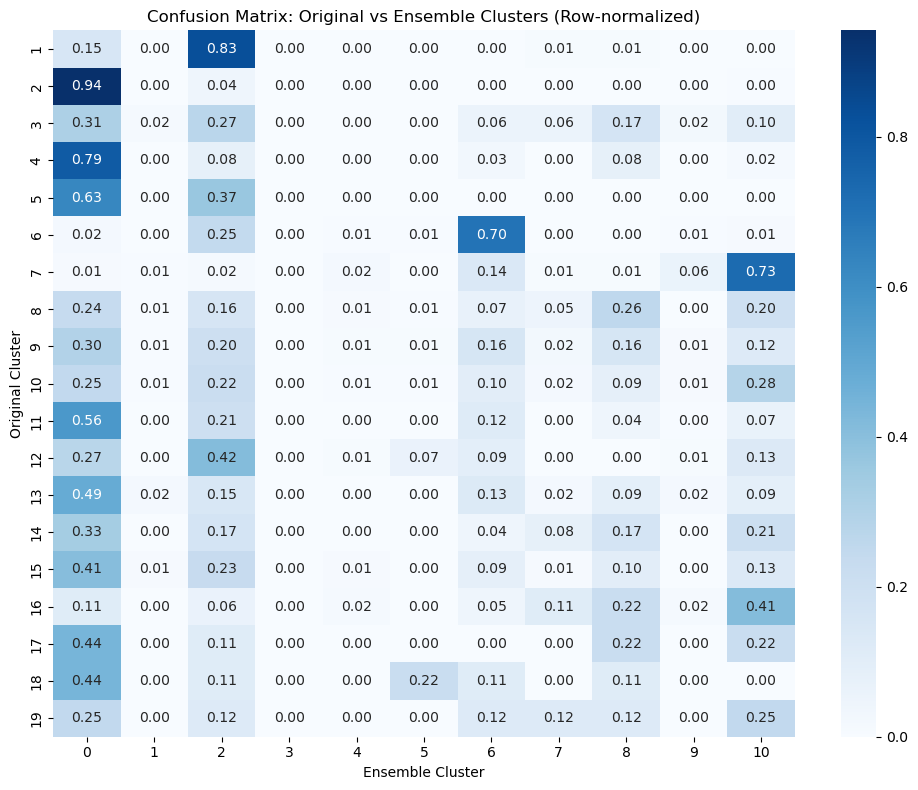

In [11]:
# Create confusion matrix
# Row-normalize data for better visualization

confusion_matrix = pd.crosstab(combined_sp.obs['groundtruth'], combined_sp.obs['ensemble'], rownames=['Original Cluster'], colnames=['Ensemble Cluster'])
confusion_matrix_normalized = confusion_matrix.div(confusion_matrix.sum(axis=1), axis=0)
plt.figure(figsize=(10,8))
sns.heatmap(confusion_matrix_normalized, annot=True, fmt='.2f', cmap='Blues')
plt.title("Confusion Matrix: Original vs Ensemble Clusters (Row-normalized)")
plt.ylabel("Original Cluster")
plt.xlabel("Ensemble Cluster")
plt.tight_layout()

X_bass_pca not found. Computing PCA for bass using combined_sp.X.
X_scanit_pca not found. Computing PCA for scanit using combined_sp.X.
X_stlearn_pca not found. Computing PCA for stlearn using combined_sp.X.
X_bayesspace_pca not found. Computing PCA for bayesspace using combined_sp.X.


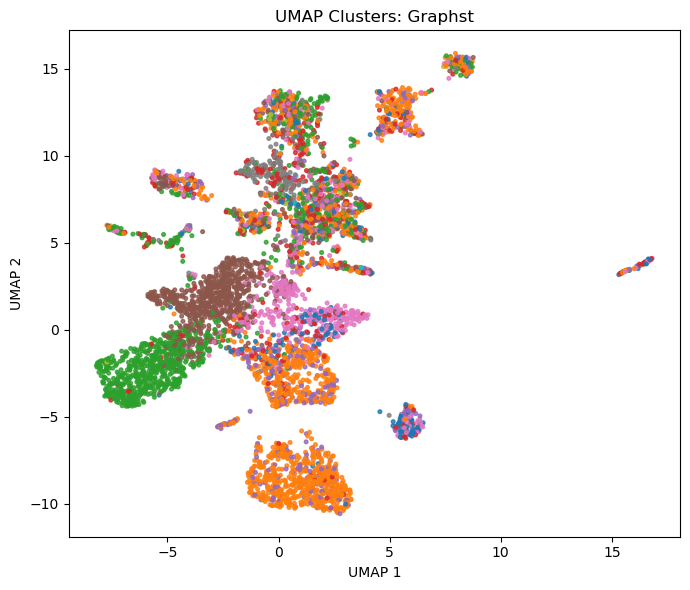

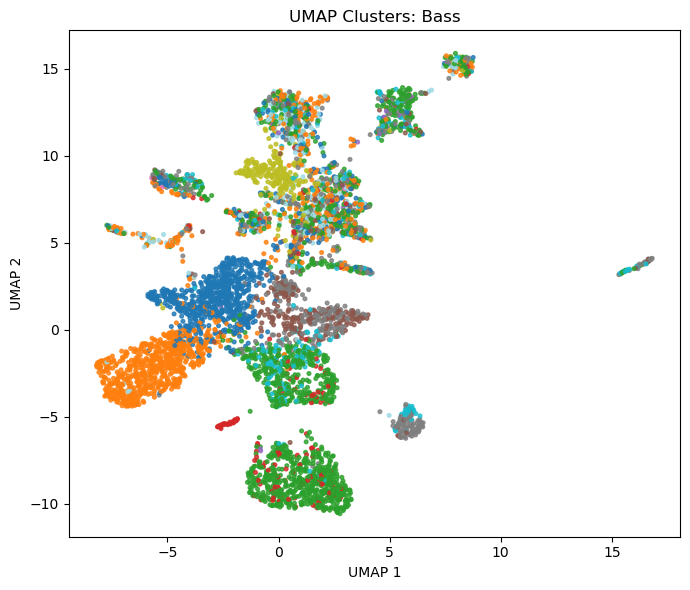

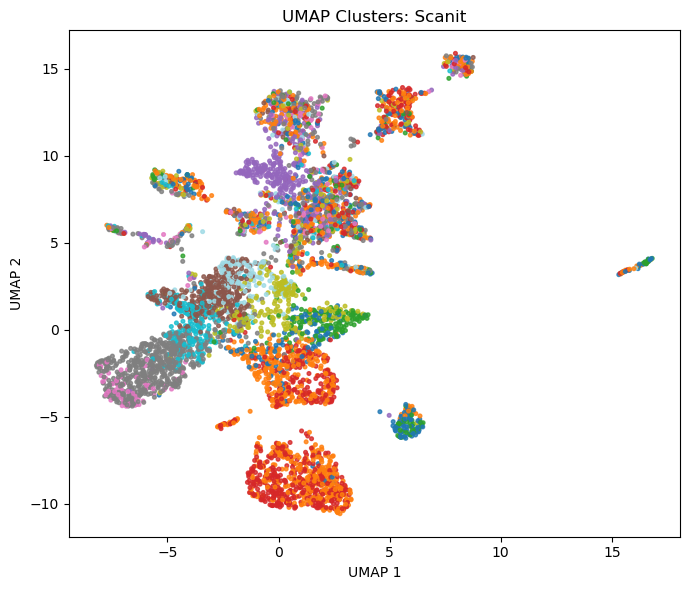

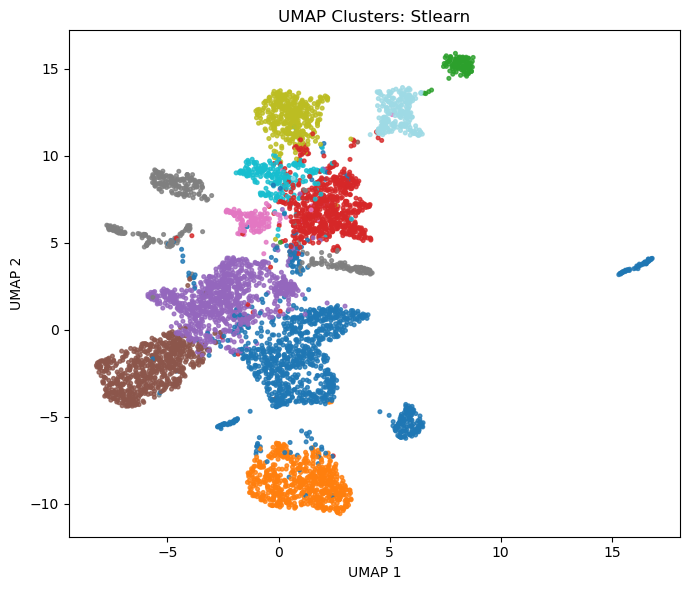

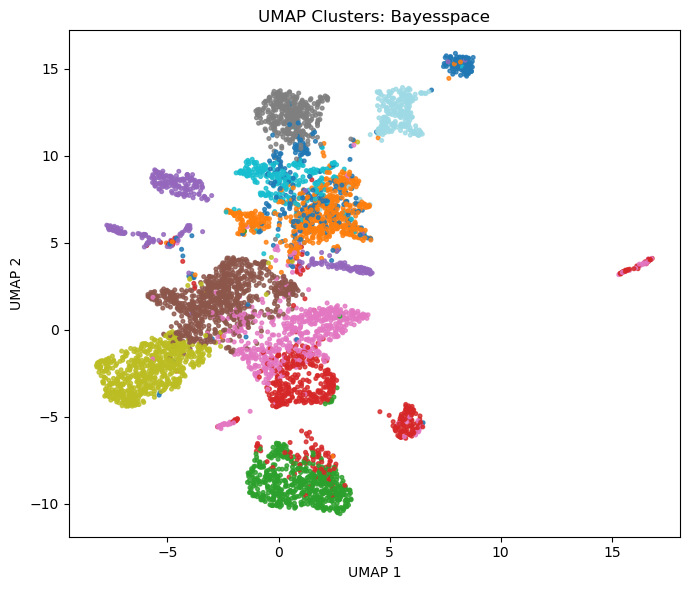

In [18]:
tool_list = ["graphst", "bass", "scanit", "stlearn", "bayesspace"]

# Plot umap for each tool
for tool in tool_list:
    pca_key = f"X_{tool}_pca"
    umap_key = f"X_{tool}_umap"
    cluster_key = f"{tool}"
    # If PCA is missing, compute it using combined_sp.X
    if pca_key not in combined_sp.obsm:
        print(f"{pca_key} not found. Computing PCA for {tool} using combined_sp.X.")
        sc.tl.pca(combined_sp)
        combined_sp.obsm[pca_key] = combined_sp.obsm["X_pca"]
    # Calculate UMAP coordinates
    sc.pp.neighbors(combined_sp, use_rep=pca_key)
    sc.tl.umap(combined_sp)
    combined_sp.obsm[umap_key] = combined_sp.obsm["X_umap"]
    x = combined_sp.obsm[umap_key][:,0]
    y_coord = combined_sp.obsm[umap_key][:,1]
    y = combined_sp.obs[cluster_key]

    cluster_codes = pd.Series(y).astype('category').cat.codes.to_numpy()
    plt.figure(figsize=(7,6))
    plt.scatter(x, y_coord, c=cluster_codes, cmap='tab20', s=7, alpha=0.8)
    plt.title(f"UMAP Clusters: {tool.capitalize()}")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.tight_layout()
    # plt.savefig(f"../data/ensemble_input/umap_{tool}_clusters.png")
    # plt.close()

X_ensemble_pca not found. Computing PCA for ensemble using combined_sp.X.
X_groundtruth_pca not found. Computing PCA for groundtruth using combined_sp.X.


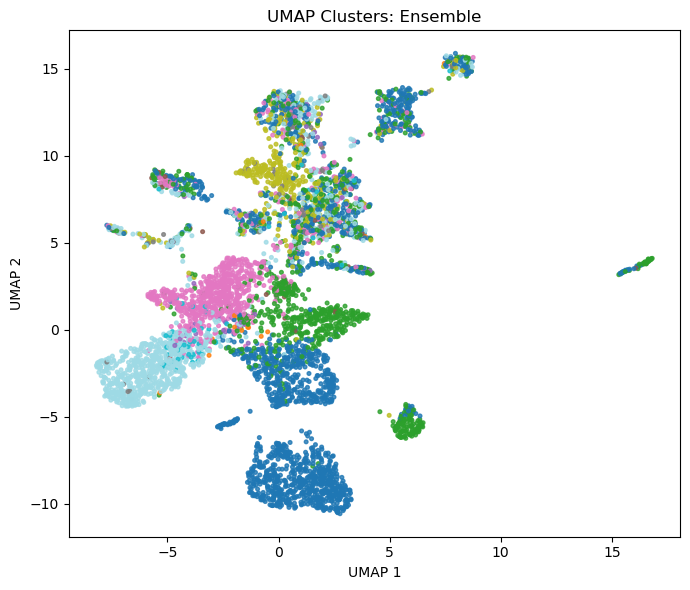

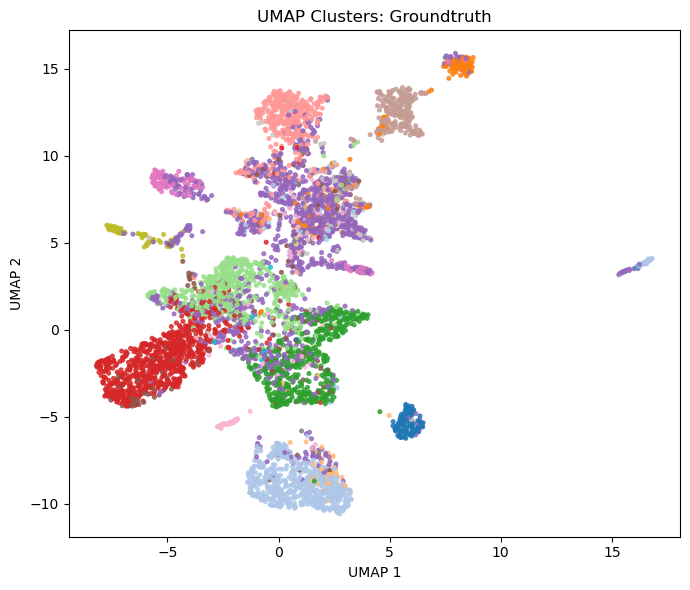

In [19]:
# Plot Umap for ensemble & groundtruth

list_res = ["ensemble", "groundtruth"]

# Plot umap for each tool
for obj in list_res:
    pca_key = f"X_{obj}_pca"
    umap_key = f"X_{obj}_umap"
    cluster_key = f"{obj}"
    # If PCA is missing, compute it using combined_sp.X
    if pca_key not in combined_sp.obsm:
        print(f"{pca_key} not found. Computing PCA for {obj} using combined_sp.X.")
        sc.tl.pca(combined_sp)
        combined_sp.obsm[pca_key] = combined_sp.obsm["X_pca"]
    # Calculate UMAP coordinates
    sc.pp.neighbors(combined_sp, use_rep=pca_key)
    sc.tl.umap(combined_sp)
    combined_sp.obsm[umap_key] = combined_sp.obsm["X_umap"]
    x = combined_sp.obsm[umap_key][:,0]
    y_coord = combined_sp.obsm[umap_key][:,1]
    y = combined_sp.obs[cluster_key]

    cluster_codes = pd.Series(y).astype('category').cat.codes.to_numpy()
    plt.figure(figsize=(7,6))
    plt.scatter(x, y_coord, c=cluster_codes, cmap='tab20', s=7, alpha=0.8)
    plt.title(f"UMAP Clusters: {obj.capitalize()}")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.tight_layout()
    # plt.savefig(f"../data/ensemble_input/umap_{obj}_clusters.png")
    # plt.close()